# Modelado y evaluación (CRISP-DM)

Continúa `01_comprension_y_preparacion.ipynb`. Cubre las fases 4 y 5 de **CRISP-DM**:

4. **Modelado**: línea base (promedio móvil) y dos candidatos del informe (regresión con
   calendario y ARIMA semanal).
5. **Evaluación**: backtesting con origen móvil, comparación contra un desempeño mínimo fijado
   antes de ver los resultados, y elección documentada.

El dataset es **sintético** (`DATASET.md`): los resultados miden qué tan bien cada modelo aprende
la pyme simulada, no una pyme real. La justificación completa está en `MODELO.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from cashpyme_modelos.evaluacion import MEJORA_MINIMA, UMBRAL_ERROR_30, elegir, evaluar, origenes_mensuales
from cashpyme_modelos.modelos import RegresionCalendario, candidatos

serie = pd.read_csv(RAIZ / "datos" / "flujo_diario_sintetico.csv", parse_dates=["fecha"], index_col="fecha")[["ingresos", "egresos"]]
guardado = json.loads((RAIZ / "resultados" / "comparacion_modelos.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
COLORES = {"Promedio móvil 28 días (línea base)": "#888780", "Regresión con calendario": "#2a78d6",
           "ARIMA semanal (SARIMA)": "#eb6834"}
pesos = lambda v, _=None: f"${v:,.0f}".replace(",", ".")

## 4. Modelado

| Modelo | Qué hace | Qué sabe del calendario |
|---|---|---|
| **Promedio móvil 28 días** (línea base) | Cada día futuro vale el promedio de los últimos 28 días | Nada |
| **Regresión con calendario** | Ridge sobre tendencia, día de la semana, mes, día del mes, feriado y último día hábil | Todo lo que se sabe de una fecha futura |
| **ARIMA semanal** | SARIMA(1,0,1)(1,0,1)[7] con la variable *cerrado* | El ciclo semanal y los días cerrados |

Los tres proyectan ingresos y egresos por separado; el flujo neto es la resta. Prophet (el otro
candidato del informe) no se incluyó: ver `MODELO.md`.

## 5. Evaluación

### Reglas, fijadas antes de comparar

In [2]:
print(f"Desempeño mínimo: error del flujo acumulado a 30 días <= {UMBRAL_ERROR_30:.0%} de los ingresos del período")
print(f"Y mejorar a la línea base en al menos {MEJORA_MINIMA:.0%} en ese indicador.")
origenes = origenes_mensuales(serie, "2025-01-01")
print(f"\nBacktesting: {len(origenes)} orígenes, del {origenes[0]:%d-%m-%Y} al {origenes[-1]:%d-%m-%Y}; "
      "cada uno entrena con todo lo anterior y proyecta 90 días.")

Desempeño mínimo: error del flujo acumulado a 30 días <= 10% de los ingresos del período
Y mejorar a la línea base en al menos 10% en ese indicador.

Backtesting: 10 orígenes, del 01-01-2025 al 01-10-2025; cada uno entrena con todo lo anterior y proyecta 90 días.


### Comparación

In [3]:
resultados = [evaluar(m, serie, origenes) for m in candidatos()]
tabla = pd.DataFrame({r.modelo: r.resumen() for r in resultados}).T
vista = tabla[["error_relativo_30", "error_relativo_60", "error_relativo_90", "error_minimo_30", "mae_diario_neto"]].copy()
vista.columns = ["Error 30 d", "Error 60 d", "Error 90 d", "Error en el mínimo de caja (30 d)", "MAE diario neto"]
vista.style.format({"Error 30 d": "{:.1%}", "Error 60 d": "{:.1%}", "Error 90 d": "{:.1%}",
                    "Error en el mínimo de caja (30 d)": pesos, "MAE diario neto": pesos})

,Error 30 d,Error 60 d,Error 90 d,Error en el mínimo de caja (30 d),MAE diario neto
Promedio móvil 28 días (línea base),15.1%,14.8%,13.8%,$749.573,$473.534
Regresión con calendario,10.7%,8.1%,5.0%,$346.946,$191.396
ARIMA semanal (SARIMA),13.5%,10.5%,9.3%,$438.923,$459.076


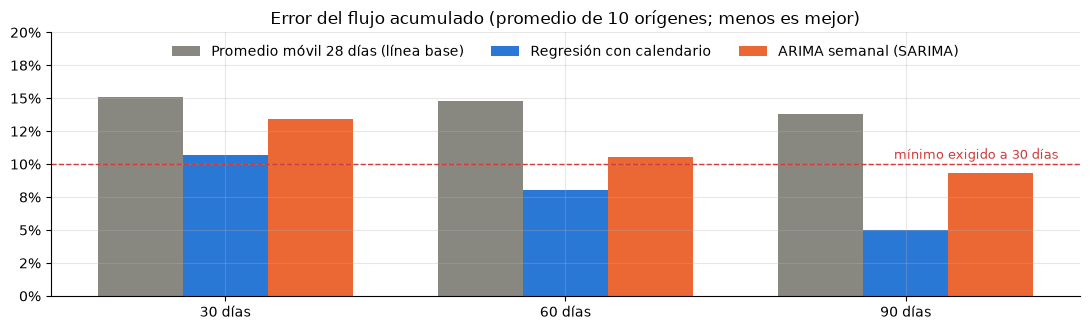

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ancho = 0.25
for i, r in enumerate(resultados):
    s = r.resumen()
    ax.bar(np.arange(3) + (i - 1) * ancho, [s[f"error_relativo_{h}"] for h in (30, 60, 90)], ancho,
           label=r.modelo, color=COLORES[r.modelo])
ax.axhline(UMBRAL_ERROR_30, color="#d03b3b", ls="--", lw=1)
ax.text(2.45, UMBRAL_ERROR_30 + 0.004, "mínimo exigido a 30 días", color="#d03b3b", ha="right", fontsize=9)
ax.set_xticks(range(3), ["30 días", "60 días", "90 días"])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Error del flujo acumulado (promedio de 10 orígenes; menos es mejor)")
ax.set_ylim(0, 0.2)
ax.legend(frameon=False, ncol=3, loc="upper center")
plt.tight_layout()

### ¿Cuánto varía de un mes a otro?

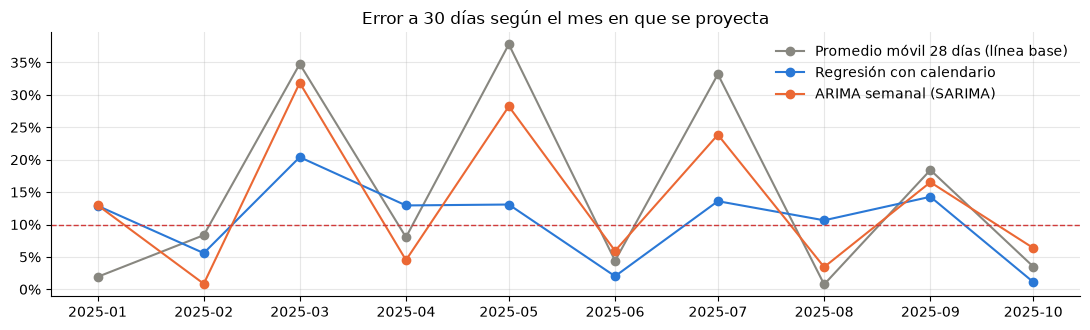

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for r in resultados:
    ax.plot(pd.to_datetime(r.por_origen["origen"]), r.por_origen["error_relativo_30"], marker="o",
            label=r.modelo, color=COLORES[r.modelo])
ax.axhline(UMBRAL_ERROR_30, color="#d03b3b", ls="--", lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Error a 30 días según el mes en que se proyecta")
ax.legend(frameon=False)
plt.tight_layout()

### Proyección contra la realidad (último origen: octubre a diciembre de 2025)

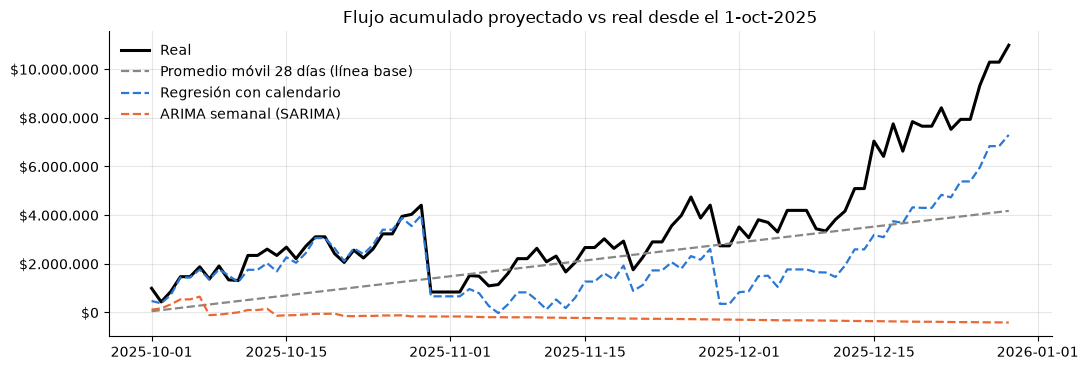

In [6]:
fig, ax = plt.subplots()
ultima = resultados[0].proyeccion_ultima
ax.plot(ultima.index, ultima["real_neto"].cumsum(), color="black", lw=2.2, label="Real")
for r in resultados:
    ax.plot(r.proyeccion_ultima.index, r.proyeccion_ultima["proyectado_neto"].cumsum(), color=COLORES[r.modelo],
            lw=1.6, ls="--", label=r.modelo)
ax.yaxis.set_major_formatter(pesos)
ax.set_title("Flujo acumulado proyectado vs real desde el 1-oct-2025")
ax.legend(frameon=False)
plt.tight_layout()

### Piso de ruido: ¿el mínimo era alcanzable?

Como el dataset es sintético, se puede simular la misma pyme con 200 semillas distintas. Lo que
cambia entre ellas es puro azar; un modelo perfecto, que conociera las reglas de la simulación,
tendría como error justamente esa variación.

In [7]:
piso = guardado["piso_de_ruido_30_dias"]
mejor = min(resultados[1:], key=lambda r: r.resumen()["error_relativo_30"])
print(f"Piso de ruido a 30 días (modelo perfecto): {piso['error_relativo_promedio']:.1%}")
print(f"Mejor candidato ({mejor.modelo}):           {mejor.resumen()['error_relativo_30']:.1%}")
print(f"Mínimo exigido:                             {UMBRAL_ERROR_30:.0%}")

Piso de ruido a 30 días (modelo perfecto): 5.1%
Mejor candidato (Regresión con calendario):           10.7%
Mínimo exigido:                             10%


El mínimo de 10 % está por encima del piso (5,1 %): es alcanzable y no hay que relajarlo. El mejor
candidato se equivoca el doble que un modelo perfecto, así que la diferencia es del modelo y no
del azar: hay margen para mejorar.

### Exploración posterior (no se usa para decidir)

Después de ver los resultados se probaron dos variantes de la regresión. Se muestran para
orientar la próxima iteración, pero **no cambian la decisión**: elegir un parámetro mirando los
mismos meses con que se evalúa infla el resultado.

In [8]:
filas = []
for alfa in (0.3, 1.0, 3.0, 10.0):
    r = evaluar(RegresionCalendario(alfa=alfa), serie, origenes).resumen()
    filas.append({"alfa (ridge)": alfa, "Error 30 d": r["error_relativo_30"], "Error 90 d": r["error_relativo_90"]})
pd.DataFrame(filas).style.format({"Error 30 d": "{:.1%}", "Error 90 d": "{:.1%}"}).hide(axis="index")

alfa (ridge),Error 30 d,Error 90 d
0.300000,11.0%,5.4%
1.000000,10.7%,5.0%
3.000000,9.6%,4.2%
10.000000,8.0%,3.6%


Una penalización mayor (alfa 3 o 10) baja el error a 30 días cerca o por debajo del 10 %. Para
usarla de verdad, alfa se tiene que elegir **dentro** de cada entrenamiento (validación con los
meses anteriores al origen) y confirmarse con datos que no se hayan mirado. Modelar las ventas
en escala logarítmica también se probó y no mejoró a 30 días (11,4 %).

## Decisión

In [9]:
eleccion = elegir(resultados)
for e in eleccion["candidatos"]:
    print(f"{e['modelo']}: error 30 d {e['error_relativo_30']:.1%} "
          f"(umbral {'OK' if e['cumple_umbral'] else 'NO'}), mejora sobre la base {e['mejora_sobre_base']:.0%} "
          f"({'OK' if e['cumple_mejora'] else 'NO'})")
print("\n" + eleccion["conclusion"])

Regresión con calendario: error 30 d 10.7% (umbral NO), mejora sobre la base 29% (OK)
ARIMA semanal (SARIMA): error 30 d 13.5% (umbral NO), mejora sobre la base 11% (OK)

Ningún candidato alcanza el desempeño mínimo (el mejor, Regresión con calendario, queda en 10.7% a 30 días contra un máximo de 10%): no se integra un modelo estadístico y el producto sigue con la proyección por documentos.


**Ningún candidato alcanza el desempeño mínimo.** La regresión con calendario es la mejor en
todas las métricas, le gana a la línea base por 29 % y cumple holgadamente a 60 y 90 días, pero
a 30 días queda en 10,7 %, sobre el máximo de 10 %. Por lo tanto no se integra un modelo
estadístico al producto en este sprint: la proyección sigue siendo la del backend, por
documentos por cobrar y por pagar.

Próximo paso: elegir alfa con validación anidada dentro de cada entrenamiento, evaluar con un
dataset no mirado (otra semilla o, mejor, datos reales) y, si pasa el mínimo, exponerlo como
servicio. Detalle en `MODELO.md`.